# Zararlı Yorum Tespiti (Toxic Comment Classification Challenge)
Çevrimiçi tartışmalarda hakaret, taciz ve tehdit insanları konuşmaktan vazgeçiriyor. Wikipedia tartışma sayfalarındaki yorumları otomatik olarak zararlılık türlerine göre sınıflandıran bir model kurmak istiyoruz.NLP kullanacağız.
Her yorum için 6 ayrı etiketi tahmin ediyoruz:
toxic (zararlı), severe_toxic(çok zararlı), obscene(müstehcen), threat(tehdit), insult (hakaret), identity_hate (kimliğe yönelik nefret)
Bu notebook'ta veriyi inceleyeceğiz, yorumları TF-IDF ile sayıya çevireceğiz, modelleri karşılaştıracağız

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sample = pd.read_csv('sample_submission.csv')

In [3]:
etiketler = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

In [4]:
train.shape

(159571, 8)

In [5]:
test.shape

(153164, 2)

In [6]:
train.isna().sum().sum()

np.int64(0)

In [7]:
test.isna().sum().sum()

np.int64(0)

In [8]:
train[['id'] + etiketler].head(3)

,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,0,0,0,0,0,0
1,000103f0d9cfb60f,0,0,0,0,0,0
2,000113f07ec002fd,0,0,0,0,0,0


In [9]:
oran = train[etiketler].mean() * 100
print('Her etiketin görülme oranı (%):')
print(oran.round(2))

Her etiketin görülme oranı (%):
toxic            9.58
severe_toxic     1.00
obscene          5.29
threat           0.30
insult           4.94
identity_hate    0.88
dtype: float64


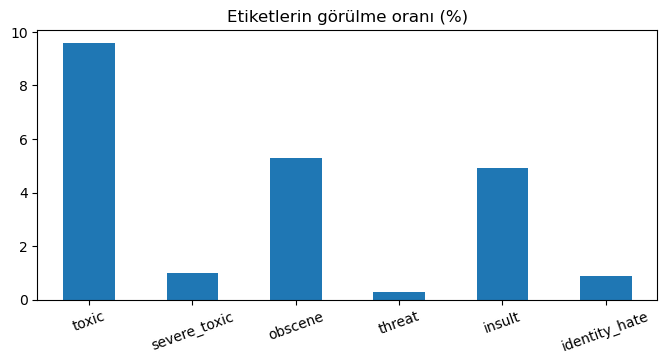

In [10]:
oran.plot(kind='bar', figsize=(8, 3.5))
plt.title('Etiketlerin görülme oranı (%)')
plt.xticks(rotation=20);

In [11]:
kac_etiket = train[etiketler].sum(axis=1)
print('Bir yorumun kaç etiketi var (yorum oranı %):')
print((kac_etiket.value_counts(normalize=True).sort_index() * 100).round(1))

Bir yorumun kaç etiketi var (yorum oranı %):
0    89.8
1     4.0
2     2.2
3     2.6
4     1.1
5     0.2
6     0.0
Name: proportion, dtype: float64


In [12]:
korelasyon = train[etiketler].corr()
print(korelasyon.round(2))

               toxic  severe_toxic  obscene  threat  insult  identity_hate
toxic           1.00          0.31     0.68    0.16    0.65           0.27
severe_toxic    0.31          1.00     0.40    0.12    0.38           0.20
obscene         0.68          0.40     1.00    0.14    0.74           0.29
threat          0.16          0.12     0.14    1.00    0.15           0.12
insult          0.65          0.38     0.74    0.15    1.00           0.34
identity_hate   0.27          0.20     0.29    0.12    0.34           1.00


Text(0.5, 1.0, 'Etiketler arası korelasyon')

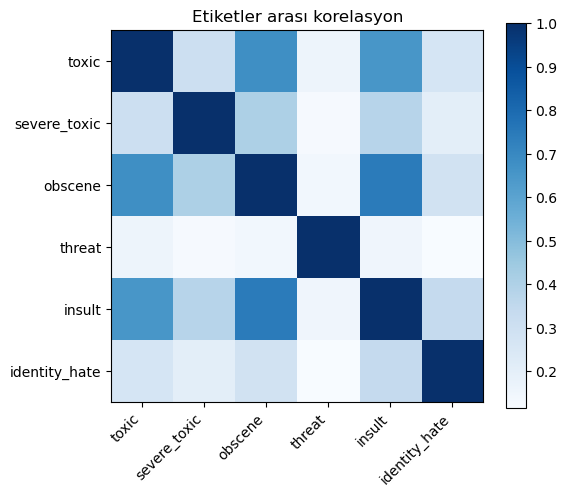

In [13]:
plt.figure(figsize=(6, 5))
plt.imshow(korelasyon, cmap='Blues')
plt.xticks(range(6), etiketler, rotation=45, ha='right')
plt.yticks(range(6), etiketler)
plt.colorbar()
plt.title('Etiketler arası korelasyon')

In [14]:
train['kelime_sayisi'] = train.comment_text.str.split().str.len()
print('Kelime sayısı (tüm yorumlar):')
print(train.kelime_sayisi.describe().round(0))
print()
print('Ortalama kelime sayısı -> zararlı:', round(train[train.toxic == 1].kelime_sayisi.mean()),
      '| zararsız:', round(train[train.toxic == 0].kelime_sayisi.mean()))

Kelime sayısı (tüm yorumlar):
count    159571.0
mean         67.0
std          99.0
min           1.0
25%          17.0
50%          36.0
75%          75.0
max        1411.0
Name: kelime_sayisi, dtype: float64

Ortalama kelime sayısı -> zararlı: 51 | zararsız: 69


In [15]:
egitim, dogrulama = train_test_split(train, test_size=0.2, random_state=42, stratify=train.toxic)
Y_e, Y_d = egitim[etiketler].values, dogrulama[etiketler].values
print('eğitim:', egitim.shape, '| doğrulama:', dogrulama.shape)

kelime_deseni = r"(?u)\b[\w']+\b"
sonuclar = {}

def ortalama_auc(Y, tahmin):
    return np.mean([roc_auc_score(Y[:, j], tahmin[:, j]) for j in range(6)])

def dene(isim, model_fn, X_e, X_d):
    tahmin = np.column_stack([model_fn().fit(X_e, Y_e[:, j]).predict_proba(X_d)[:, 1] for j in range(6)])
    sonuclar[isim] = ortalama_auc(Y_d, tahmin)
    print(isim, '-> ortalama AUC:', round(sonuclar[isim], 4))
    return tahmin

eğitim: (127656, 9) | doğrulama: (31915, 9)


In [16]:
bow = CountVectorizer(min_df=3, token_pattern=kelime_deseni)
B_e, B_d = bow.fit_transform(egitim.comment_text), bow.transform(dogrulama.comment_text)
_ = dene('Naive Bayes (Bag of Words)', lambda: MultinomialNB(alpha=0.5), B_e, B_d)

Naive Bayes (Bag of Words) -> ortalama AUC: 0.9211


In [17]:
tfidf_cift = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=300000, sublinear_tf=True, token_pattern=kelime_deseni)
T2_e, T2_d = tfidf_cift.fit_transform(egitim.comment_text), tfidf_cift.transform(dogrulama.comment_text)
_ = dene('Naive Bayes (TF-IDF 1-2 kelime)', lambda: MultinomialNB(alpha=0.1), T2_e, T2_d)

Naive Bayes (TF-IDF 1-2 kelime) -> ortalama AUC: 0.9349


In [18]:
tfidf_tek = TfidfVectorizer(min_df=3, sublinear_tf=True, token_pattern=kelime_deseni)
T1_e, T1_d = tfidf_tek.fit_transform(egitim.comment_text), tfidf_tek.transform(dogrulama.comment_text)
_ = dene('Logistic Regression (TF-IDF 1 kelime)', lambda: LogisticRegression(C=4, solver='liblinear'), T1_e, T1_d)

Logistic Regression (TF-IDF 1 kelime) -> ortalama AUC: 0.9823


In [19]:
_ = dene('Logistic Regression (TF-IDF 1-2 kelime)', lambda: LogisticRegression(C=4, solver='liblinear'), T2_e, T2_d)

Logistic Regression (TF-IDF 1-2 kelime) -> ortalama AUC: 0.9823


In [20]:
tahmin_dogrulama = dene('Logistic Regression (TF-IDF 1 kelime, dengeli)',
                        lambda: LogisticRegression(C=1, solver='liblinear', class_weight='balanced'), T1_e, T1_d)

Logistic Regression (TF-IDF 1 kelime, dengeli) -> ortalama AUC: 0.9836


In [21]:
tablo = pd.DataFrame({'Ortalama AUC (büyük iyi)': sonuclar}).sort_values('Ortalama AUC (büyük iyi)', ascending=False).round(4)
print(tablo)

                                                Ortalama AUC (büyük iyi)
Logistic Regression (TF-IDF 1 kelime, dengeli)                    0.9836
Logistic Regression (TF-IDF 1-2 kelime)                           0.9823
Logistic Regression (TF-IDF 1 kelime)                             0.9823
Naive Bayes (TF-IDF 1-2 kelime)                                   0.9349
Naive Bayes (Bag of Words)                                        0.9211


Text(0.5, 1.0, 'Doğrulama ortalama AUC (büyük iyi)')

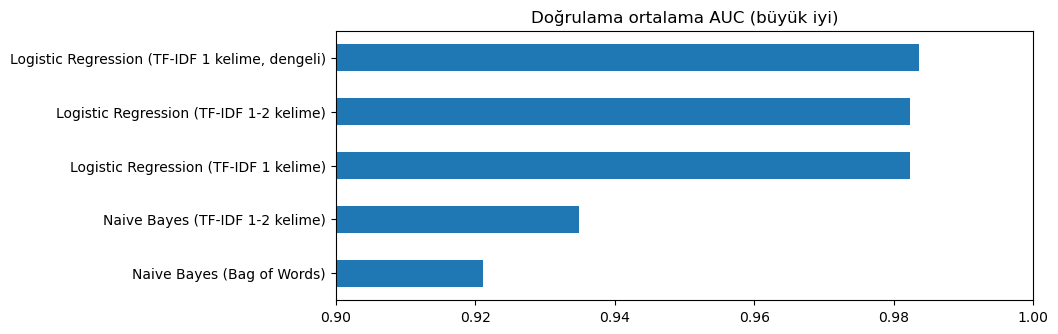

In [22]:
tablo.iloc[::-1].plot(kind='barh', legend=False, figsize=(9, 3.5), xlim=(0.9, 1.0))
plt.title('Doğrulama ortalama AUC (büyük iyi)')

Logistic Regression, Naive Bayes'ten çok daha iyi. Naive Bayes her kelimeyi birbirinden bağımsız sayıyor ve nadir etiketlerde (özellikle threat) zayıf kalıyor.
Tek kelimeye 2 kelimelik grupları eklemek skoru değiştirmedi, ama modeli çok büyüttü (47 bin yerine 300 bin özellik). Bu yüzden tek kelimeyle devam ediyoruz.
class_weight=balanced ve daha güçlü düzenlileştirme skoru biraz daha artırdı. Seçtiğimiz model bu.

In [23]:
for j, e in enumerate(etiketler):
    print(f'{e:14s} AUC: {roc_auc_score(Y_d[:, j], tahmin_dogrulama[:, j]):.4f}')

toxic          AUC: 0.9756
severe_toxic   AUC: 0.9881
obscene        AUC: 0.9883
threat         AUC: 0.9845
insult         AUC: 0.9817
identity_hate  AUC: 0.9832


In [24]:
model = Pipeline([('vec', TfidfVectorizer(min_df=3, sublinear_tf=True, token_pattern=kelime_deseni)),
                  ('model', MultiOutputClassifier(LogisticRegression(C=1, solver='liblinear', class_weight='balanced')))])
model.fit(train.comment_text, train[etiketler].values)

olasilik = np.column_stack([p[:, 1] for p in model.predict_proba(test.comment_text)])
sonuc = pd.DataFrame(olasilik, columns=etiketler)
sonuc.insert(0, 'id', test.id.values)
sonuc.to_csv('sonuc1.csv', index=False)
print(sonuc.shape)

(153164, 7)


In [25]:
sonuc.head()

,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,0.999886,0.914648,0.999896,0.651279,0.997474,0.948651
1,0000247867823ef7,0.008785,0.003052,0.002963,0.000565,0.009421,0.010671
2,00013b17ad220c46,0.093255,0.014778,0.047179,0.003458,0.063798,0.024298
3,00017563c3f7919a,0.009083,0.016094,0.007542,0.005644,0.010877,0.002672
4,00017695ad8997eb,0.098885,0.020646,0.044943,0.017415,0.027091,0.011300


In [26]:
print('sütunlar sample ile aynı mı:', list(sonuc.columns) == list(sample.columns))
print('id\'ler aynı mı           :', (sonuc.id.values == sample.id.values).all())
print('boş değer var mı          :', sonuc[etiketler].isna().any().any())
print('olasılık aralığı          :', round(sonuc[etiketler].values.min(), 4), '-', round(sonuc[etiketler].values.max(), 4))

sütunlar sample ile aynı mı: True
id'ler aynı mı           : True
boş değer var mı          : False
olasılık aralığı          : 0.0 - 1.0


In [27]:
if os.path.exists('test_labels.csv'):
    gercek = pd.read_csv('test_labels.csv')
    puanlanan = gercek.toxic != -1                   
    test_auc = [roc_auc_score(gercek.loc[puanlanan, e], sonuc.loc[puanlanan.values, e]) for e in etiketler]
    for e, a in zip(etiketler, test_auc):
        print(f'{e:14s} test AUC: {a:.4f}')
    test_ortalama_auc = float(np.mean(test_auc))
    print()
    print(f'Ortalama test AUC: {test_ortalama_auc:.4f}   (puanlanan yorum sayısı: {int(puanlanan.sum())})')
else:
    test_ortalama_auc = None
    print('test_labels.csv klasörde yok, bu adım atlandı.')

toxic          test AUC: 0.9607
severe_toxic   test AUC: 0.9842
obscene        test AUC: 0.9758
threat         test AUC: 0.9911
insult         test AUC: 0.9695
identity_hate  test AUC: 0.9802

Ortalama test AUC: 0.9769   (puanlanan yorum sayısı: 63978)


In [28]:
with open('model.pkl', 'wb') as f:
    pickle.dump(model, f)
print('model.pkl kaydedildi')

model.pkl kaydedildi


- Bu, 6 ayrı etiketi aynı anda tahmin ettiğimiz bir çok etiketli sınıflandırma problemi. Her etiket için ayrı bir Logistic Regression eğittik.
- Veri çok dengesiz. Bu yüzden accuracy yerine AUC kullanılıyor ve dengeli sınıf ağırlığı (class_weight='balanced') işe yaradı.
- İkili kelime grupları skoru artırmadı, modeli büyüttü; bu yüzden tek kelimeyle devam ettik.